# ParaEMT HELICS Frequency Visualization

Adapted from `HELICS_8_STREAM_FREQUENCY_DEMO.ipynb` to read the Recorder outputs of an
OEDISI frontend run instead of saved HELICS CSV files.

1. `load_helics_streams()` finds every Recorder subscribed to a ParaEMT stream (using the
   run's `wiring.json`), loads its feather file, and converts timestamps to simulation seconds.
2. `prepare_frequency_analysis()` performs an unweighted breadth-first search (BFS) on the
   PSS/E RAW network topology to find the generators nearest Gen 31.
3. `plot_frequency_single_column()` draws one panel each for the Bus 6533 PLL frequency,
   Gen 31, and every generator tied at the minimum BFS distance from Gen 31.

Per-generator frequency is `generator_rotor_speed / (2*pi)`, so generators sharing a bus keep
separate curves.

**Required Recorders:** `ibr_frequency` and `generator_rotor_speed`. Other ParaEMT streams are
loaded if a Recorder is attached to them.

In [1]:
from __future__ import annotations

import csv
import json
import re
from collections import defaultdict, deque
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.feather as pf
from IPython.display import display

# DATA_DIR will be set automatically when copied to a run
DATA_DIR = r""

RUN_DIR = Path(DATA_DIR) if DATA_DIR else Path.cwd()
BUILD_DIR = RUN_DIR / 'build'
OUTPUT_DIR = RUN_DIR / 'notebook_outputs'

PARAEMT_STREAMS = (
    'voltage',
    'current',
    'frequency',
    'ibr_frequency',
    'bus_electrical_power',
    'generator_electrical_power',
    'generator_reactive_power',
    'tie_line_flow',
    'generator_rotor_speed',
)
REQUIRED_STREAMS = ('ibr_frequency', 'generator_rotor_speed')

# Matches the default in ParaEMT's step1_test.py when simulation.oedi_start_timestamp is unset.
DEFAULT_START_TIMESTAMP = '2026-01-01 00:00:00'

print(f'Run directory: {RUN_DIR}')

Run directory: /Users/jmckinse/Programming/oedisi-frontend-app/server/runs/dev/76444a95b3d64d1aad85b27f055229cd


## 1. Locate and Load the Recorded Streams

Each Recorder subscribes to one `paraemt/<stream>` publication. The run's `wiring.json` links
tell us which Recorder holds which stream, so Recorder names do not matter.

The returned value is a `dict[str, pandas.DataFrame]` keyed by stream name. Each frame has one
column per signal ID plus `time` in seconds from the start of the simulation.

In [2]:
def find_paraemt_recordings(run_dir: str | Path) -> tuple[dict, dict[str, Path]]:
    '''Return the ParaEMT component and a {stream: feather path} map from wiring.json.'''

    run_dir = Path(run_dir)
    wiring = json.loads((run_dir / 'wiring.json').read_text(encoding='utf-8'))
    components = {component['name']: component for component in wiring['components']}

    paraemt = [
        component for component in wiring['components']
        if 'simulation' in component.get('parameters', {})
        and 'powerflow' in component.get('parameters', {})
    ]
    if len(paraemt) != 1:
        raise ValueError(f'Expected one ParaEMT component in wiring.json; found {len(paraemt)}.')
    paraemt = paraemt[0]

    recordings: dict[str, Path] = {}
    for link in wiring['links']:
        target = components[link['target']]
        if link['source'] != paraemt['name'] or target['type'] != 'Recorder':
            continue
        feather_name = target['parameters']['feather_filename']
        recordings[link['source_port']] = run_dir / 'build' / target['name'] / feather_name
    return paraemt, recordings


def load_helics_streams(
    recordings: dict[str, Path],
    start_timestamp: str = DEFAULT_START_TIMESTAMP,
) -> dict[str, pd.DataFrame]:
    '''Load and validate every recorded ParaEMT stream.'''

    missing = [stream for stream in REQUIRED_STREAMS if stream not in recordings]
    if missing:
        raise KeyError(
            f'No Recorder is attached to ParaEMT stream(s) {missing}. '
            'Add a Recorder for each in the frontend and run again.'
        )

    start = pd.Timestamp(start_timestamp)
    streams: dict[str, pd.DataFrame] = {}
    for stream_name, path in recordings.items():
        if not path.exists():
            raise FileNotFoundError(f'{stream_name}: {path} does not exist.')

        frame = pf.read_feather(path)
        if frame.empty:
            raise ValueError(f'{path.name} is empty.')
        frame['time'] = (pd.to_datetime(frame['time']) - start).dt.total_seconds()
        if not frame['time'].is_monotonic_increasing:
            raise ValueError(f'{path.name}: time is not monotonic.')
        if frame.isna().any().any():
            raise ValueError(f'{path.name} contains NaN.')
        numeric = frame.select_dtypes(include=[np.number]).to_numpy(copy=False)
        if np.isinf(numeric).any():
            raise ValueError(f'{path.name} contains Inf.')

        streams[stream_name] = frame

    return streams

In [3]:
paraemt_component, recordings = find_paraemt_recordings(RUN_DIR)
paraemt_parameters = paraemt_component['parameters']
start_timestamp = paraemt_parameters['simulation'].get(
    'oedi_start_timestamp', DEFAULT_START_TIMESTAMP
)

helics_streams = load_helics_streams(recordings, start_timestamp)

stream_summary = pd.DataFrame(
    [
        {
            'stream': name,
            'recorded': name in helics_streams,
            'rows': len(helics_streams[name]) if name in helics_streams else None,
            'signal_columns': len(helics_streams[name].columns) - 1 if name in helics_streams else None,
            'time_start_s': helics_streams[name]['time'].iloc[0] if name in helics_streams else None,
            'time_end_s': helics_streams[name]['time'].iloc[-1] if name in helics_streams else None,
        }
        for name in PARAEMT_STREAMS
    ]
)
display(stream_summary)

,stream,recorded,rows,signal_columns,time_start_s,time_end_s
0,voltage,True,10000.0,729.0,0.0,9.999
1,current,False,NaN,NaN,NaN,NaN
2,frequency,False,NaN,NaN,NaN,NaN
3,ibr_frequency,True,10000.0,243.0,0.0,9.999
4,bus_electrical_power,False,NaN,NaN,NaN,NaN
5,generator_electrical_power,True,10000.0,105.0,0.0,9.999
6,generator_reactive_power,False,NaN,NaN,NaN,NaN
7,tie_line_flow,False,NaN,NaN,NaN,NaN
8,generator_rotor_speed,True,10000.0,105.0,0.0,9.999


## 2. RAW Topology and BFS Helper Functions

Active branches and transformers are undirected edges with unit weight. The RAW file comes from
the copy of the ParaEMT component in the run's build directory, so it always matches the case
that was simulated.

In [4]:
# ParaEMT case 7.3 (step1_test.py) is the WECC 240-bus system.
CASE_RAW_FILES = {
    7.3: 'models/240bus_psse/240busWECC_2018_PSS_PQLoad_fixedshunt_rm0load_2600_2619G_mod.raw',
}
system_n = paraemt_parameters['simulation']['systemN']
if system_n not in CASE_RAW_FILES:
    raise KeyError(f'No RAW file is known for systemN={system_n}; add it to CASE_RAW_FILES.')
RAW_PATH = BUILD_DIR / paraemt_component['name'] / CASE_RAW_FILES[system_n]
print(f'RAW topology: {RAW_PATH}')

RAW topology: /Users/jmckinse/Programming/oedisi-frontend-app/server/runs/dev/76444a95b3d64d1aad85b27f055229cd/build/paraemt/models/240bus_psse/240busWECC_2018_PSS_PQLoad_fixedshunt_rm0load_2600_2619G_mod.raw


In [5]:
def build_raw_topology(raw_path: str | Path) -> dict[int, set[int]]:
    '''Build an undirected graph from active RAW branches and transformers.'''

    graph: dict[int, set[int]] = defaultdict(set)
    section = ''
    for line in Path(raw_path).read_text(encoding='utf-8', errors='replace').splitlines():
        lower = line.lower()
        if 'begin branch data' in lower:
            section = 'branch'
            continue
        if 'end of branch data' in lower:
            section = ''
        if 'begin transformer data' in lower:
            section = 'transformer'
            continue
        if 'end of transformer data' in lower:
            section = ''
        if section not in {'branch', 'transformer'}:
            continue

        try:
            fields = next(csv.reader([line], skipinitialspace=True))
            if section == 'branch':
                buses = [int(fields[0]), int(fields[1])]
                status = int(float(fields[13])) if len(fields) > 13 else 1
            else:
                buses = [int(fields[0]), int(fields[1])]
                third_bus = int(fields[2])
                if third_bus != 0:
                    buses.append(third_bus)
                status = int(float(fields[11])) if len(fields) > 11 else 1
        except (ValueError, IndexError, StopIteration):
            continue
        if status == 0:
            continue

        for index, first_bus in enumerate(buses):
            for second_bus in buses[index + 1:]:
                graph[first_bus].add(second_bus)
                graph[second_bus].add(first_bus)

    return dict(graph)


def parse_generator_units(columns) -> list[dict[str, object]]:
    '''Extract generator number, bus number, and unit ID from stream columns.'''

    pattern = re.compile(r'^gen(\d+)_bus(\d+)_id(.+)$')
    units = []
    for column in columns:
        match = pattern.match(str(column))
        if match is not None:
            units.append(
                {
                    'generator': int(match.group(1)),
                    'bus': int(match.group(2)),
                    'id': match.group(3),
                    'column': str(column),
                }
            )
    return units


def bfs_distances_and_parents(
    graph: dict[int, set[int]],
    start_bus: int,
) -> tuple[dict[int, int], dict[int, int | None]]:
    '''Return unit-weight BFS distances and one parent per visited bus.'''

    distances = {start_bus: 0}
    parents: dict[int, int | None] = {start_bus: None}
    queue = deque([start_bus])
    while queue:
        bus = queue.popleft()
        for neighbor in sorted(graph.get(bus, set())):
            if neighbor in distances:
                continue
            distances[neighbor] = distances[bus] + 1
            parents[neighbor] = bus
            queue.append(neighbor)
    return distances, parents


def restore_path(parents: dict[int, int | None], start: int, end: int) -> list[int]:
    '''Restore one shortest path from the BFS parent map.'''

    path = [end]
    while path[-1] != start:
        path.append(int(parents[path[-1]]))
    return list(reversed(path))

## 3. Prepare the Frequency Analysis

Prepares the Bus 6533 PLL-frequency series, the Gen 31 frequency series, and one
rotor-speed-derived frequency series for every generator tied at the minimum BFS distance from
Gen 31. Generator IDs come from the `generator_rotor_speed` columns.

In [6]:
def prepare_frequency_analysis(
    streams: dict[str, pd.DataFrame],
    raw_path: str | Path,
    pll_bus: int = 6533,
    target_generator: int = 31,
) -> dict[str, object]:
    '''Prepare the PLL, target-generator, and nearest-generator frequency panels.'''

    ibr_frequency = streams['ibr_frequency']
    generator_rotor_speed = streams['generator_rotor_speed']

    generator_units = parse_generator_units(generator_rotor_speed.columns)
    target_matches = [unit for unit in generator_units if unit['generator'] == target_generator]
    if len(target_matches) != 1:
        raise ValueError(
            f'Expected one Gen {target_generator}; found {len(target_matches)}.'
        )
    target = target_matches[0]

    graph = build_raw_topology(raw_path)
    target_bus = int(target['bus'])
    distances, parents = bfs_distances_and_parents(graph, target_bus)
    candidates = [
        unit for unit in generator_units
        if unit['generator'] != target_generator and int(unit['bus']) in distances
    ]
    minimum_distance = min(distances[int(unit['bus'])] for unit in candidates)

    nearest_units = []
    for unit in candidates:
        bus = int(unit['bus'])
        if distances[bus] == minimum_distance:
            nearest_units.append(
                {
                    **unit,
                    'distance': minimum_distance,
                    'shortest_path': restore_path(parents, target_bus, bus),
                }
            )
    nearest_units.sort(key=lambda unit: (unit['generator'], unit['bus'], unit['id']))

    if str(pll_bus) not in ibr_frequency.columns:
        raise KeyError(f'Missing PLL frequency for bus {pll_bus}.')

    def generator_frequency_frame(unit: dict[str, object]) -> pd.DataFrame:
        generator_id = str(unit['column'])
        frame = generator_rotor_speed[['time', generator_id]].copy()
        frame['frequency_Hz'] = frame[generator_id] / (2.0 * np.pi)
        return frame[['time', 'frequency_Hz']]

    nearest_generator_frequencies = []
    for unit in nearest_units:
        nearest_generator_frequencies.append(
            {
                **unit,
                'frequency_source': (
                    f"paraemt/generator_rotor_speed ID {unit['column']} / (2*pi)"
                ),
                'frequency': generator_frequency_frame(unit),
            }
        )

    return {
        'all_streams': streams,
        'pll_bus': pll_bus,
        'pll_frequency': ibr_frequency[['time', str(pll_bus)]].rename(
            columns={str(pll_bus): 'frequency_Hz'}
        ).copy(),
        'target_generator': target,
        'target_frequency': generator_frequency_frame(target),
        'minimum_bfs_distance': minimum_distance,
        'nearest_units': nearest_units,
        'nearest_generator_frequencies': nearest_generator_frequencies,
    }

In [7]:
frequency_analysis = prepare_frequency_analysis(
    helics_streams,
    RAW_PATH,
    pll_bus=6533,
    target_generator=31,
)

nearest_table = pd.DataFrame(frequency_analysis['nearest_units'])[
    ['generator', 'bus', 'id', 'distance', 'shortest_path']
]
display(nearest_table)
print('Minimum BFS distance:', frequency_analysis['minimum_bfs_distance'])
print('Number of separately retained nearby generators:', len(nearest_table))
print('Expected plot count:', 2 + len(nearest_table))

,generator,bus,id,distance,shortest_path
0,91,6433,C,4,"[2634, 2604, 6404, 6403, 6433]"
1,92,6433,E,4,"[2634, 2604, 6404, 6403, 6433]"
2,93,6433,G,4,"[2634, 2604, 6404, 6403, 6433]"
3,94,6533,C,4,"[2634, 2604, 6504, 6503, 6533]"
4,95,6533,G,4,"[2634, 2604, 6504, 6503, 6533]"
5,96,6533,H,4,"[2634, 2604, 6504, 6503, 6533]"
6,100,7032,C,4,"[2634, 2604, 6504, 7002, 7032]"
7,101,7032,G,4,"[2634, 2604, 6504, 7002, 7032]"
8,102,7032,H,4,"[2634, 2604, 6504, 7002, 7032]"


Minimum BFS distance: 4
Number of separately retained nearby generators: 9
Expected plot count: 11


## 4. Single-Column Plot with One Panel per Signal

The dashed line marks the first enabled event (generator trip, forced oscillation, bus fault,
state perturbation, or step change) that occurs within the simulation.

In [8]:
def plot_frequency_single_column(
    analysis: dict[str, object],
    event_time: float | None = None,
) -> tuple[plt.Figure, np.ndarray]:
    '''Plot PLL, target-generator, and nearby-generator frequencies separately.'''

    nearest_generators = analysis['nearest_generator_frequencies']
    panel_count = 2 + len(nearest_generators)
    fig, axes = plt.subplots(
        panel_count,
        1,
        figsize=(13, 2.7 * panel_count),
        sharex=True,
    )
    axes = np.atleast_1d(axes)

    pll_bus = int(analysis['pll_bus'])
    pll = analysis['pll_frequency']
    axes[0].plot(pll['time'], pll['frequency_Hz'], color='tab:red', linewidth=1.1)
    axes[0].set_title(f'Bus {pll_bus} PLL Frequency — paraemt/ibr_frequency')

    target = analysis['target_generator']
    target_frequency = analysis['target_frequency']
    axes[1].plot(
        target_frequency['time'],
        target_frequency['frequency_Hz'],
        color='black',
        linewidth=1.2,
    )
    axes[1].set_title(
        f"Gen {target['generator']}, Bus {target['bus']}, ID {target['id']} Frequency "
        f"— paraemt/generator_rotor_speed ID {target['column']} / (2*pi)"
    )

    colors = plt.get_cmap('tab10')
    for row, generator_record in enumerate(nearest_generators, start=2):
        frame = generator_record['frequency']
        axes[row].plot(
            frame['time'],
            frame['frequency_Hz'],
            color=colors((row - 2) % 10),
            linewidth=1.1,
        )
        axes[row].set_title(
            f"Gen {generator_record['generator']}, Bus {generator_record['bus']}, "
            f"ID {generator_record['id']}, BFS Distance {generator_record['distance']} "
            f"— {generator_record['frequency_source']}"
        )

    for axis in axes:
        if event_time is not None:
            axis.axvline(event_time, color='gray', linestyle='--', linewidth=1.0)
        axis.set_ylabel('Frequency (Hz)')
        axis.grid(True, alpha=0.3)
        axis.set_xlim(left=0.0)
    axes[-1].set_xlabel('Simulation Time (s)')
    fig.tight_layout()
    return fig, axes

Event time: None
Saved: /Users/jmckinse/Programming/oedisi-frontend-app/server/runs/dev/76444a95b3d64d1aad85b27f055229cd/notebook_outputs/bus6533_pll_and_gen31_nearest_generators_frequency.png
Number of plotted panels: 11


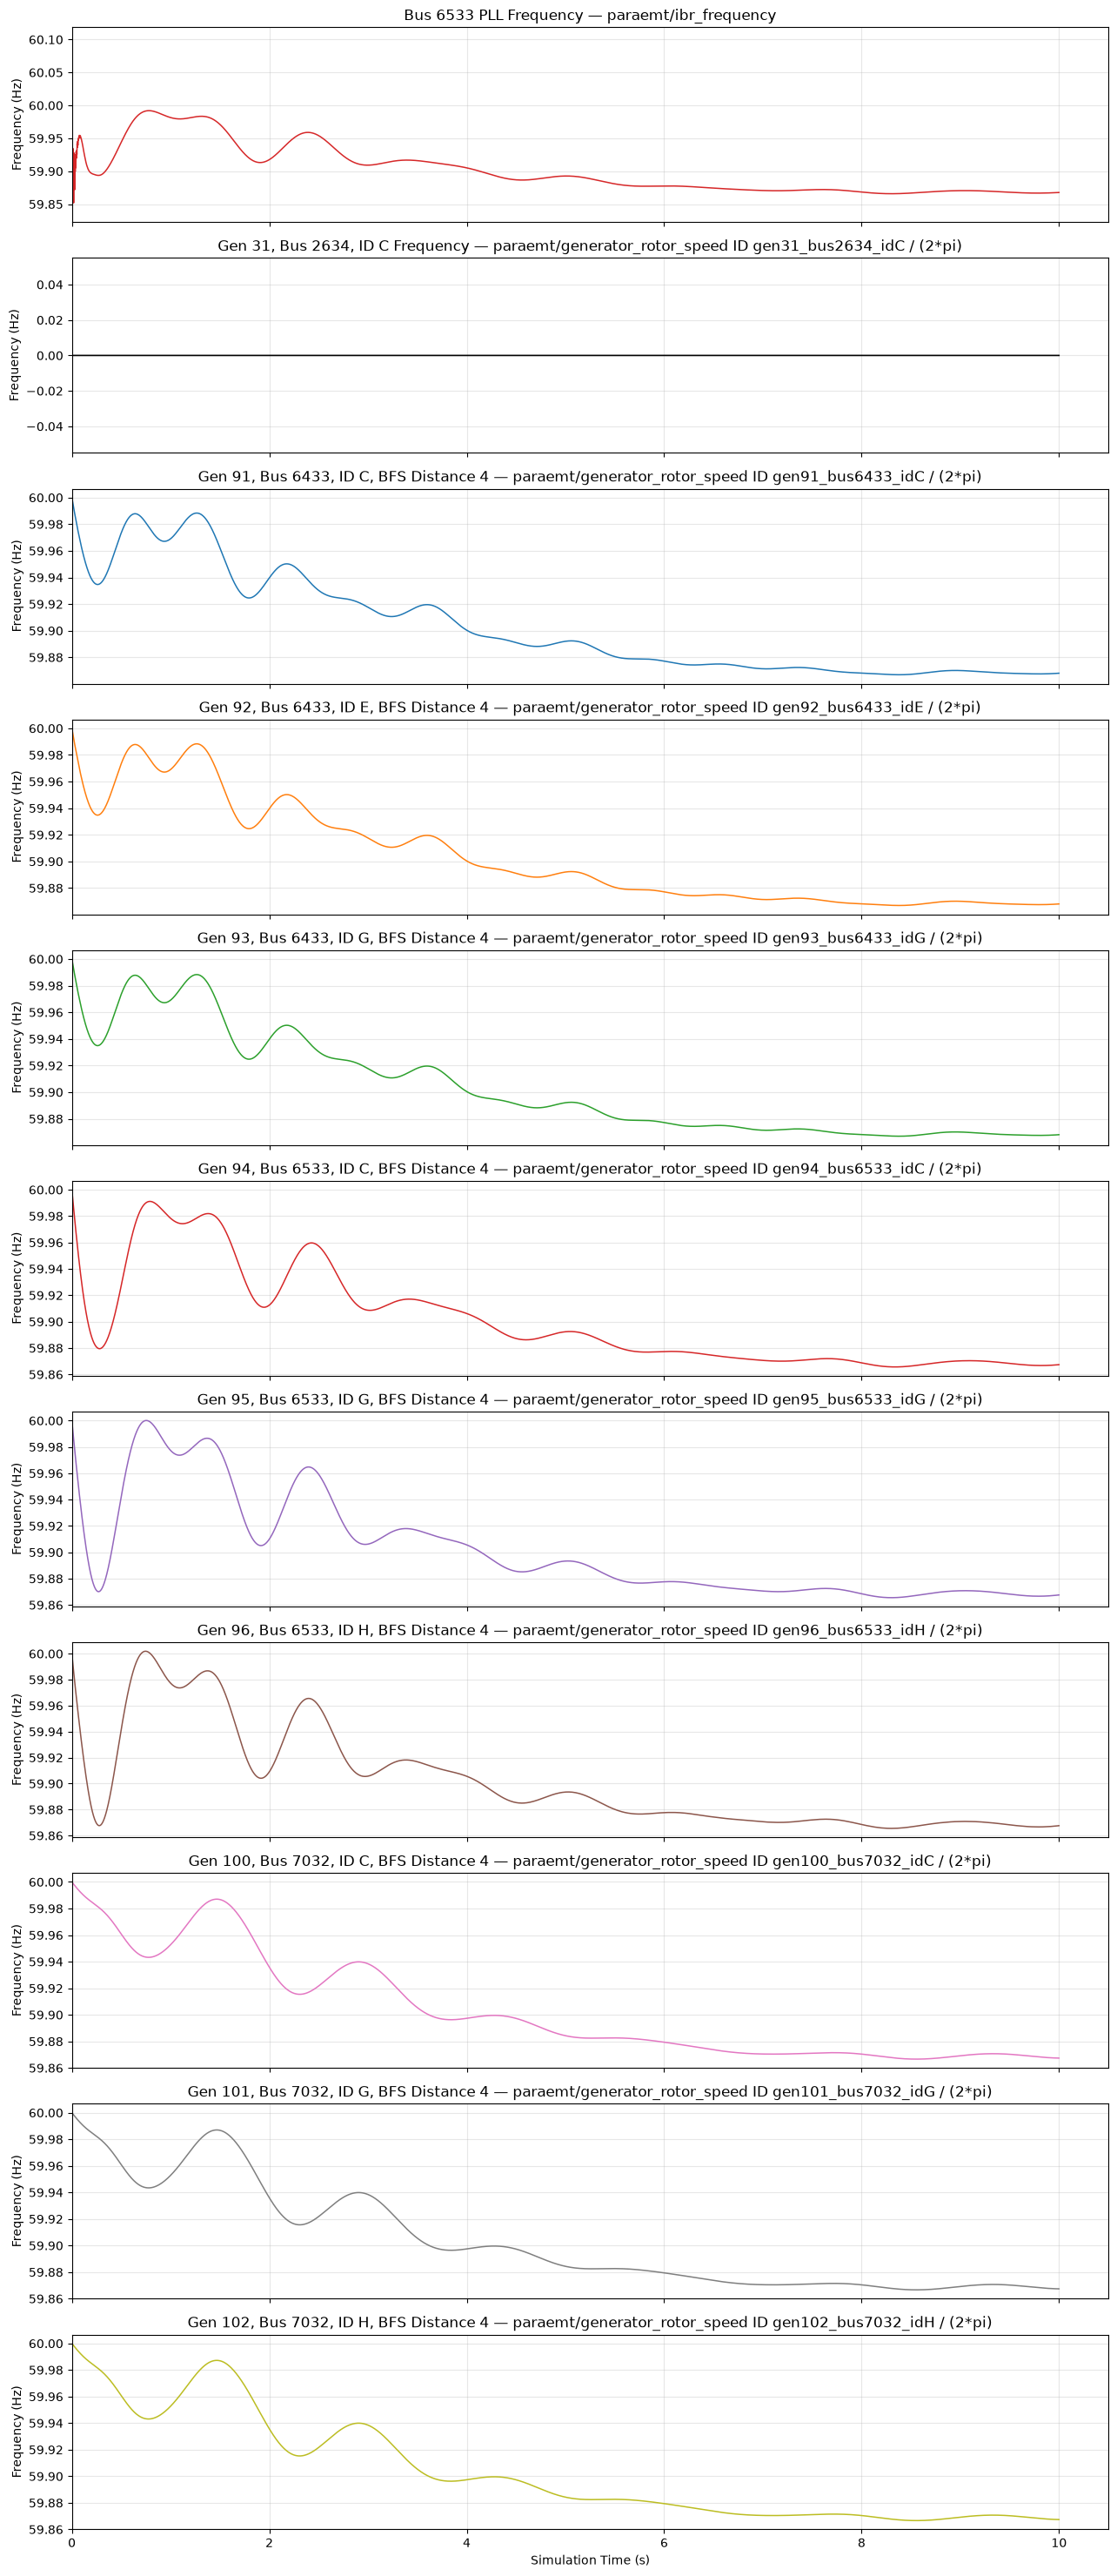

In [9]:
# Mark the first enabled ParaEMT event that occurs within the simulation.
EVENT_TIME_KEYS = {
    'gen_trip': 'time',
    'forced_oscillation': 'start_time',
    'bus_fault': 'time',
    'state_perturbation': 'time',
    'step_change': 'time',
}
t_end = paraemt_parameters['simulation']['t_end']
event_times = [
    paraemt_parameters[event][key]
    for event, key in EVENT_TIME_KEYS.items()
    if paraemt_parameters.get(event, {}).get('enabled')
    and paraemt_parameters[event][key] <= t_end
]
event_time = min(event_times, default=None)
print(f'Event time: {event_time}')

fig, axes = plot_frequency_single_column(frequency_analysis, event_time=event_time)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
output_path = OUTPUT_DIR / 'bus6533_pll_and_gen31_nearest_generators_frequency.png'
fig.savefig(output_path, dpi=200, bbox_inches='tight')
print(f'Saved: {output_path}')
print(f'Number of plotted panels: {len(axes)}')
plt.show()

## Accessing the Returned Data

Every recorded stream is directly accessible:

```python
generator_rotor_speed_df = helics_streams['generator_rotor_speed']
ibr_frequency_df = helics_streams['ibr_frequency']
```

The per-generator plotting records are under `frequency_analysis['nearest_generator_frequencies']`.